# Library Import

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Mount dataset

In [2]:
df = pd.read_csv('../data/Telco-Customer-Churn.csv')
print(df.shape)

(7043, 21)


# Kualitas data

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing per kolom:')
print(df.isna().sum()[df.isna().sum() > 0])
print('Baris duplikat:', df.duplicated().sum())
print('customerID duplikat:', df['customerID'].duplicated().sum())
print(df[df['TotalCharges'].isna()][['tenure', 'Churn']])

Missing per kolom:
TotalCharges    11
dtype: int64
Baris duplikat: 0
customerID duplikat: 0
      tenure Churn
488        0    No
753        0    No
936        0    No
1082       0    No
1340       0    No
3331       0    No
3826       0    No
4380       0    No
5218       0    No
6670       0    No
6754       0    No


# Target dan Statistik Deskriptif

In [4]:
df['y'] = (df['Churn'] == 'Yes').astype(int)
print(df['y'].value_counts(normalize=True))
print(df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(2))
print(df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].agg(['mean', 'median']).round(2))

y
0    0.73463
1    0.26537
Name: proportion, dtype: float64
        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7032.00
mean     32.37           64.76       2283.30
std      24.56           30.09       2266.77
min       0.00           18.25         18.80
25%       9.00           35.50        401.45
50%      29.00           70.35       1397.48
75%      55.00           89.85       3794.74
max      72.00          118.75       8684.80
      tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2555.34  1683.60
Yes    17.98   10.0          74.44  79.65      1531.80   703.55


# Outlier (IQR)

In [5]:
for c in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(c, 'outlier:', n_out, 'skew:', round(df[c].skew(), 2))

tenure outlier: 0 skew: 0.24
MonthlyCharges outlier: 0 skew: -0.22
TotalCharges outlier: 0 skew: 0.96


# Tingkat churn per kategori, kelompok tenure, korelasi

In [6]:
print("===== Tingkat Churn =====\n")
for c in ['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen']:
    print(df.groupby(c)['y'].agg(['count', 'mean']).round(3))

print("\n===== Kelompok Tenure =====\n")

df['tenure_group'] = pd.cut(df['tenure'], [-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
print(df.groupby('tenure_group', observed=True)['y'].agg(['count', 'mean']).round(3))

print("\n===== Korelasi Variabel =====\n")
print(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'y']].corr().round(3))

===== Tingkat Churn =====

                count   mean
Contract                    
Month-to-month   3875  0.427
One year         1473  0.113
Two year         1695  0.028
                 count   mean
InternetService              
DSL               2421  0.190
Fiber optic       3096  0.419
No                1526  0.074
                           count   mean
PaymentMethod                          
Bank transfer (automatic)   1544  0.167
Credit card (automatic)     1522  0.152
Electronic check            2365  0.453
Mailed check                1612  0.191
               count   mean
SeniorCitizen              
0               5901  0.236
1               1142  0.417

===== Kelompok Tenure =====

              count   mean
tenure_group              
0-12           2186  0.474
13-24          1024  0.287
25-48          1594  0.204
49-72          2239  0.095

===== Korelasi Variabel =====

                tenure  MonthlyCharges  TotalCharges      y
tenure           1.000           0.248    

# Visualisasi EDA
grafik disimpan ke folder `figures/` di root repository.

In [7]:
# Pengaturan tema dan folder output
os.makedirs('../figures', exist_ok=True)
sns.set_theme(style='whitegrid')
warna = {'No': '#4C78A8', 'Yes': '#E45756'}
rata_churn = df['y'].mean() * 100

### Gambar 1. Distribusi target Churn

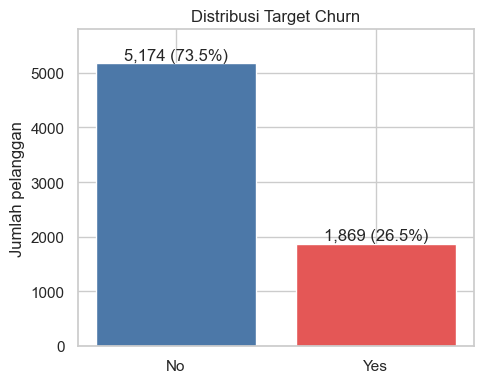

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
jumlah = df['Churn'].value_counts()
ax.bar(jumlah.index, jumlah.values, color=[warna[k] for k in jumlah.index])
for i, v in enumerate(jumlah.values):
    ax.text(i, v + 60, f'{v:,} ({v / len(df):.1%})', ha='center')
ax.set_ylim(0, jumlah.max() * 1.12)
ax.set_title('Distribusi Target Churn')
ax.set_ylabel('Jumlah pelanggan')
plt.tight_layout()
plt.savefig('../figures/fig1_distribusi_churn.png', dpi=150)
plt.show()

### Gambar 2. Distribusi tenure, MonthlyCharges, dan TotalCharges menurut Churn

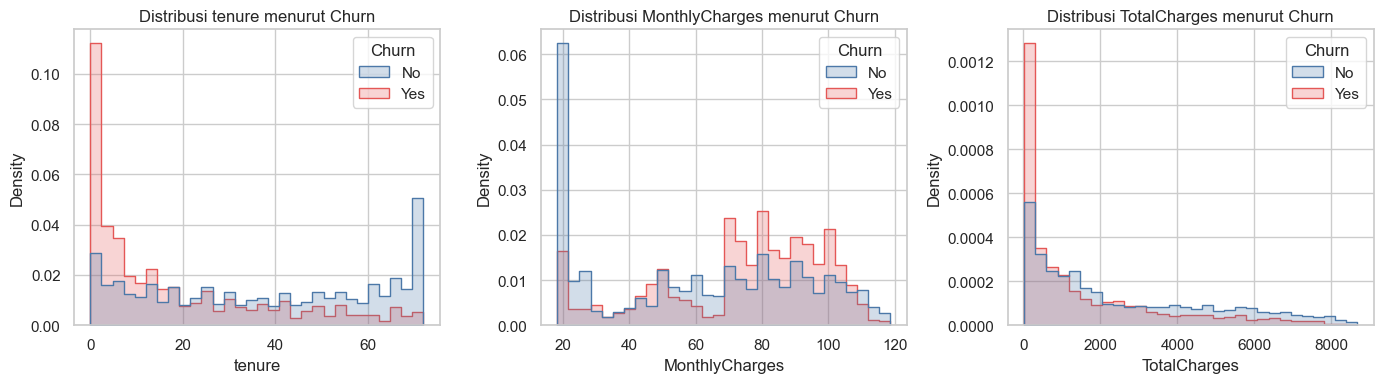

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.histplot(data=df, x=c, hue='Churn', bins=30, element='step',
                 stat='density', common_norm=False, palette=warna, ax=ax)
    ax.set_title(f'Distribusi {c} menurut Churn')
plt.tight_layout()
plt.savefig('../figures/fig2_distribusi_numerik.png', dpi=150)
plt.show()

### Gambar 3. Tingkat churn per kelompok tenure

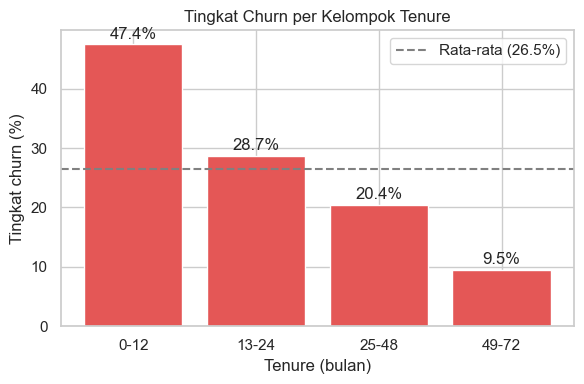

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
laju = df.groupby('tenure_group', observed=True)['y'].mean() * 100
ax.bar(laju.index.astype(str), laju.values, color='#E45756')
for i, v in enumerate(laju.values):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center')
ax.axhline(rata_churn, ls='--', color='gray', label=f'Rata-rata ({rata_churn:.1f}%)')
ax.set_xlabel('Tenure (bulan)')
ax.set_ylabel('Tingkat churn (%)')
ax.set_title('Tingkat Churn per Kelompok Tenure')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/fig3_churn_per_tenure.png', dpi=150)
plt.show()

### Gambar 4. Tingkat churn per kategori (6 panel)

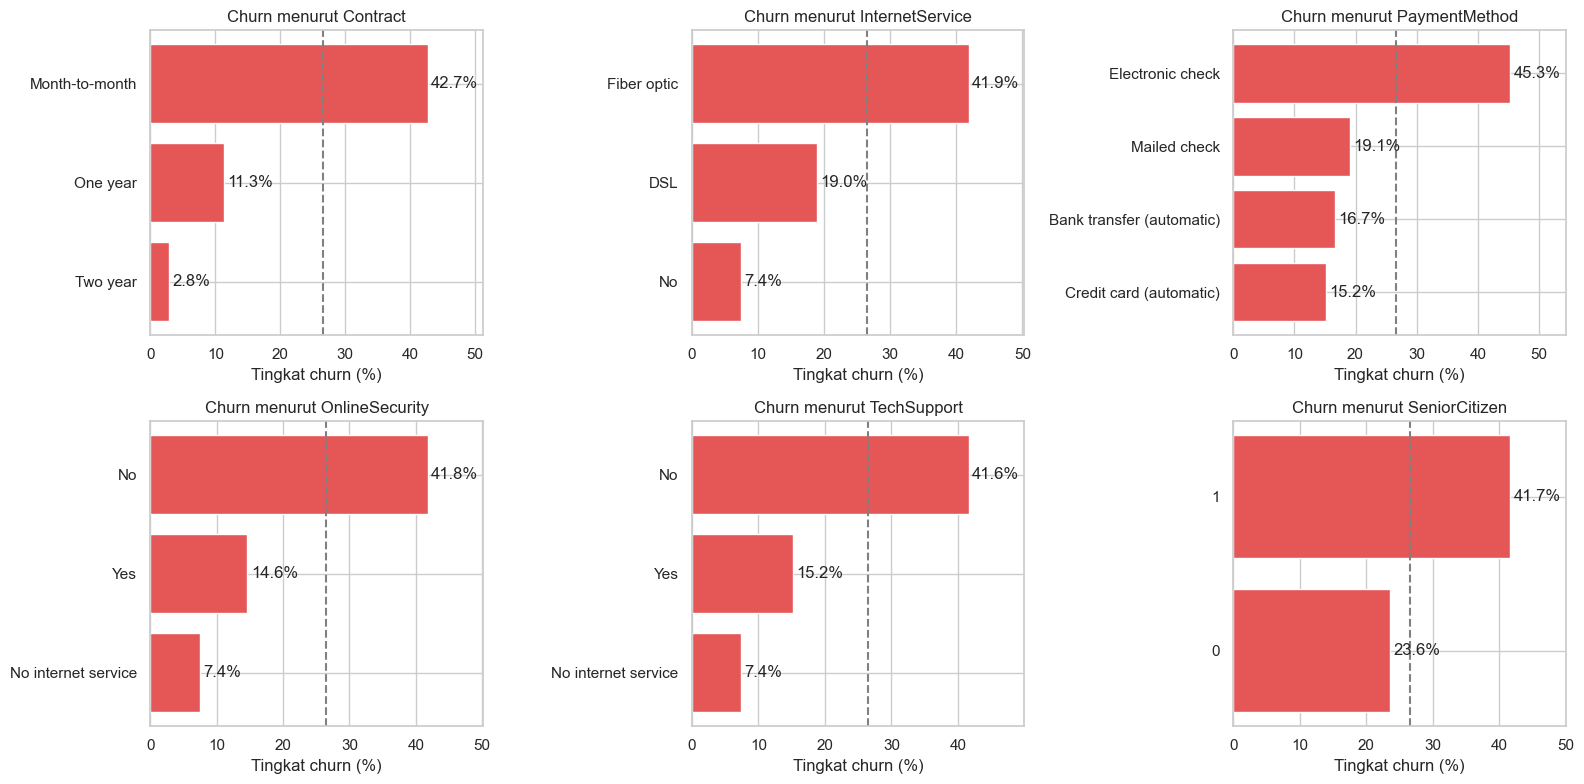

In [11]:
kolom = ['Contract', 'InternetService', 'PaymentMethod',
         'OnlineSecurity', 'TechSupport', 'SeniorCitizen']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), kolom):
    laju = (df.groupby(c)['y'].mean() * 100).sort_values()
    ax.barh(laju.index.astype(str), laju.values, color='#E45756')
    for i, v in enumerate(laju.values):
        ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
    ax.axvline(rata_churn, ls='--', color='gray')
    ax.set_title(f'Churn menurut {c}')
    ax.set_xlabel('Tingkat churn (%)')
    ax.set_xlim(0, max(laju.values) * 1.2)
plt.tight_layout()
plt.savefig('../figures/fig4_churn_per_kategori.png', dpi=150)
plt.show()

### Gambar 5. Heatmap korelasi variabel numerik dan Churn

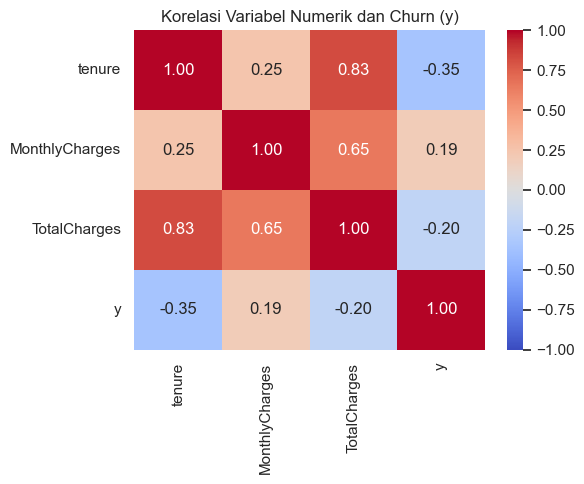

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
korelasi = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'y']].corr()
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Korelasi Variabel Numerik dan Churn (y)')
plt.tight_layout()
plt.savefig('../figures/fig5_korelasi.png', dpi=150)
plt.show()